<a href="https://colab.research.google.com/github/dikshasa17/Retail_Sales_DataWarehouse_Project/blob/main/SQL_Warehouse_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Retail Sales Data Warehouse**

#### **Business objective**

Understand sales performance, customer behavior, product performance, and trends to help businesses make better decisions.

**We'll perform these analyses:**

Analysis	What we'll find

1. Database setup	Load Gold tables
2. Data exploration	Understand columns, rows, data types
3. KPI analysis	Total sales, quantity, orders, customers
4. Magnitude analysis	Sales by category, country
5. Ranking analysis	Top products, top customers
6. Customer analysis	Spending and customer segments
7. Time analysis	Monthly and yearly trends
8. Cumulative analysis	Running sales and cumulative revenue
9. Performance analysis	Product sales vs average
10. Part-to-whole	Revenue contribution percentage
11. Reports	Summary charts and visualizations
12. Insights	Real business conclusions

**Export your Gold tables from SQL Server**

  In SSMS, export these 3 tables/views as CSV files:

- gold.fact_sales
- gold.dim_customers
- gold.dim_products

In [1]:
#Install libraries
!pip install duckdb pandas matplotlib -q

# DuckDB → SQL queries inside Python/Colab
# Pandas → Data manipulation
# Matplotlib → Charts

In [2]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
#Upload Gold CSV files
uploaded = files.upload()

Saving gold.dim_customers.csv to gold.dim_customers.csv
Saving gold.dim_products.csv to gold.dim_products.csv
Saving gold.fact_sales.csv to gold.fact_sales.csv


In [5]:
#Load CSVs into Pandas
fact_sales = pd.read_csv("gold.fact_sales.csv")
dim_customers = pd.read_csv("gold.dim_customers.csv")
dim_products = pd.read_csv("gold.dim_products.csv")

print("Files loaded successfully!")

Files loaded successfully!


In [8]:
#Create our SQL environment
#We are creating a temporary analytical database inside Colab.

con = duckdb.connect(database=":memory:")

con.register("fact_sales_df", fact_sales)
con.register("dim_customers_df", dim_customers)
con.register("dim_products_df", dim_products)

con.execute("""
    CREATE TABLE fact_sales AS
    SELECT * FROM fact_sales_df
""")

con.execute("""
    CREATE TABLE dim_customers AS
    SELECT * FROM dim_customers_df
""")

con.execute("""
    CREATE TABLE dim_products AS
    SELECT * FROM dim_products_df
""")

print("Tables created in DuckDB!")

Tables created in DuckDB!


### **1. Exploratory Data Analysis (EDA)**
Before analysing business performance, a Data Analyst or Data Engineer should understand what the data actually contains.


In [9]:

#Check table sizes
#Business question: How much data is available in each Gold table?

query = """
SELECT 'fact_sales' AS table_name, COUNT(*) AS row_count
FROM fact_sales

UNION ALL

SELECT 'dim_customers', COUNT(*)
FROM dim_customers

UNION ALL

SELECT 'dim_products', COUNT(*)
FROM dim_products
"""

con.execute(query).df()

,table_name,row_count
0,fact_sales,60398
1,dim_customers,18484
2,dim_products,295


In [10]:
# Explore the columns
print("FACT SALES COLUMNS")
print(fact_sales.columns.tolist())

print("\nCUSTOMER COLUMNS")
print(dim_customers.columns.tolist())

print("\nPRODUCT COLUMNS")
print(dim_products.columns.tolist())

FACT SALES COLUMNS
['order_number', 'product_key', 'customer_key', 'order_date', 'shipping_date', 'due_date', 'sales_amount', 'quantity', 'price']

CUSTOMER COLUMNS
['customer_key', 'customer_id', 'customer_number', 'first_name', 'last_name', 'country', 'marital_status', 'gender', 'birthdate', 'create_date']

PRODUCT COLUMNS
['product_key', 'product_id', 'product_number', 'product_name', 'category_id', 'category', 'subcategory', 'maintenance', 'cost', 'product_line', 'start_date']


In [11]:
# View sample records
print("FACT SALES")
display(fact_sales.head(5))

print("CUSTOMERS")
display(dim_customers.head(5))

print("PRODUCTS")
display(dim_products.head(5))

FACT SALES


,order_number,product_key,customer_key,order_date,shipping_date,due_date,sales_amount,quantity,price
0,SO43773,19,5527,2011-01-16,2011-01-23,2011-01-28,3578,1,3578
1,SO43775,10,28,2011-01-16,2011-01-23,2011-01-28,3400,1,3400
2,SO43803,19,10742,2011-01-22,2011-01-29,2011-02-03,3578,1,3578
3,SO43815,16,5495,2011-01-24,2011-01-31,2011-02-05,3578,1,3578
4,SO43839,16,16674,2011-01-28,2011-02-04,2011-02-09,3578,1,3578


CUSTOMERS


,customer_key,customer_id,customer_number,first_name,last_name,country,marital_status,gender,birthdate,create_date
0,1,11000,AW00011000,Jon,Yang,Australia,Married,Male,1971-10-06,2025-10-06
1,2,11001,AW00011001,Eugene,Huang,Australia,Single,Male,1976-05-10,2025-10-06
2,3,11002,AW00011002,Ruben,Torres,Australia,Married,Male,1971-02-09,2025-10-06
3,4,11003,AW00011003,Christy,Zhu,Australia,Single,Female,1973-08-14,2025-10-06
4,5,11004,AW00011004,Elizabeth,Johnson,Australia,Single,Female,1979-08-05,2025-10-06


PRODUCTS


,product_key,product_id,product_number,product_name,category_id,category,subcategory,maintenance,cost,product_line,start_date
0,1,210,FR-R92B-58,HL Road Frame - Black- 58,CO_RF,Components,Road Frames,Yes,0,Road,2003-01-07
1,2,211,FR-R92R-58,HL Road Frame - Red- 58,CO_RF,Components,Road Frames,Yes,0,Road,2003-01-07
2,3,348,BK-M82B-38,Mountain-100 Black- 38,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain,2011-01-07
3,4,349,BK-M82B-42,Mountain-100 Black- 42,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain,2011-01-07
4,5,350,BK-M82B-44,Mountain-100 Black- 44,BI_MB,Bikes,Mountain Bikes,Yes,1898,Mountain,2011-01-07


In [12]:
#Check missing values
print("Missing values in Fact Sales:")
display(fact_sales.isnull().sum())

print("\nMissing values in Customers:")
display(dim_customers.isnull().sum())

print("\nMissing values in Products:")
display(dim_products.isnull().sum())

Missing values in Fact Sales:


,0
order_number,0
product_key,0
customer_key,0
order_date,19
shipping_date,0
due_date,0
sales_amount,0
quantity,0
price,0



Missing values in Customers:


,0
customer_key,0
customer_id,0
customer_number,0
first_name,0
last_name,0
country,0
marital_status,0
gender,4569
birthdate,17
create_date,0



Missing values in Products:


,0
product_key,0
product_id,0
product_number,0
product_name,0
category_id,0
category,7
subcategory,7
maintenance,7
cost,0
product_line,17


In [14]:
# Check duplicates
print("Fact Sales duplicates:", fact_sales.duplicated().sum())
print("Customer duplicates:", dim_customers.duplicated().sum())
print("Product duplicates:", dim_products.duplicated().sum())


# These checks help us understand the dataset's completeness, structure, and potential data quality problems before we interpret the business results.

Fact Sales duplicates: 0
Customer duplicates: 0
Product duplicates: 0


#### **2. KPI Analysis — overall business performance**

Calculate business KPIs

Business questions:

- How much revenue did the business generate?
- How many items were sold?
- How many orders were placed?
- How many customers purchased?
- What is the average selling price?

In [15]:
query = """
SELECT
    SUM(sales_amount) AS total_revenue,
    SUM(quantity) AS total_quantity_sold,
    COUNT(DISTINCT order_number) AS total_orders,
    COUNT(DISTINCT customer_key) AS total_customers,
    AVG(price) AS average_price
FROM fact_sales
"""

kpi = con.execute(query).df()
display(kpi)

,total_revenue,total_quantity_sold,total_orders,total_customers,average_price
0,29356250.0,60423.0,27659,18484,486.037783


What each KPI tells us

- Total revenue → money generated from sales
- Total quantity → units sold
- Total orders → order volume
- Total customers → customers who purchased
- Average price → average price of products sold per fact row

In [16]:
# Magnitude Analysis
# How much is being contributed by each category, country, product, or customer?

#Sales by product category
query = """
SELECT
    p.category,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_quantity,
    COUNT(DISTINCT f.order_number) AS total_orders
FROM fact_sales f
LEFT JOIN dim_products p
    ON f.product_key = p.product_key
GROUP BY p.category
ORDER BY total_sales DESC
"""

category_sales = con.execute(query).df()
display(category_sales)

,category,total_sales,total_quantity,total_orders
0,Bikes,28316272.0,15205.0,15205
1,Accessories,700262.0,36112.0,18208
2,Clothing,339716.0,9106.0,7461


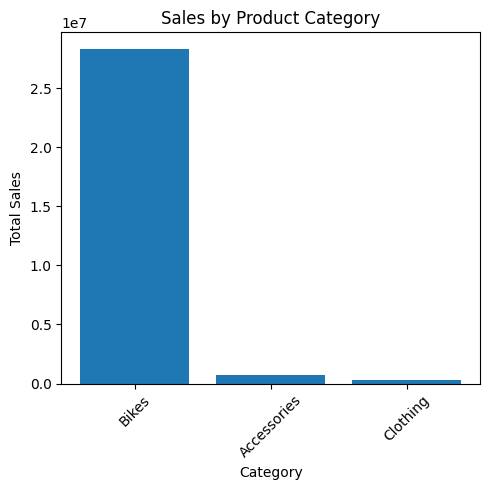

In [18]:
#Visualize category sales
plt.figure(figsize=(5, 5))

plt.bar(
    category_sales["category"],
    category_sales["total_sales"]
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
#Sales by country
query = """
SELECT
    c.country,
    SUM(f.sales_amount) AS total_sales,
    COUNT(DISTINCT f.order_number) AS total_orders,
    COUNT(DISTINCT f.customer_key) AS total_customers
FROM fact_sales f
LEFT JOIN dim_customers c
    ON f.customer_key = c.customer_key
GROUP BY c.country
ORDER BY total_sales DESC
"""

country_sales = con.execute(query).df()
display(country_sales)


,country,total_sales,total_orders,total_customers
0,Australia,9060172.0,6718,3591
1,United States,3849939.0,3809,3391
2,United Kingdom,3391376.0,3031,1913
3,US,3005297.0,2528,1500
4,France,2643751.0,2484,1810
5,USA,2307091.0,2893,2591
6,Canada,1977738.0,3375,1571
7,DE,1550341.0,993,566
8,Germany,1343725.0,1491,1214
9,,226820.0,337,337


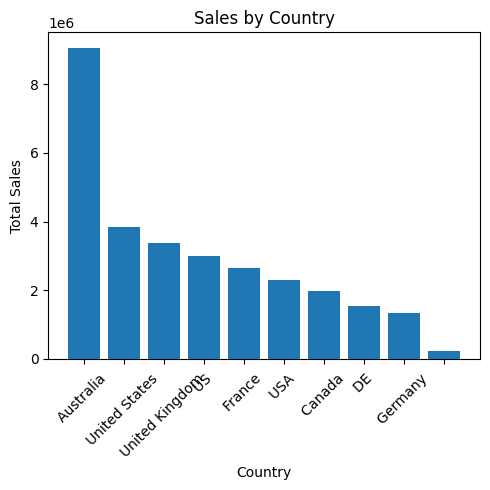

In [20]:
# Plot country performance
plt.figure(figsize=(5, 5))

plt.bar(
    country_sales["country"],
    country_sales["total_sales"]
)

plt.title("Sales by Country")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Interpretation: Identify the highest-revenue markets and the countries contributing the least sales.

### **3. Ranking Analysis**
Ranking is used to find top-performing and underperforming entities.

In [21]:
#Top 10 products by revenue
query = """
SELECT
    p.product_name,
    p.category,
    SUM(f.sales_amount) AS total_sales,
    SUM(f.quantity) AS total_quantity_sold
FROM fact_sales f
LEFT JOIN dim_products p
    ON f.product_key = p.product_key
GROUP BY
    p.product_name,
    p.category
ORDER BY total_sales DESC
LIMIT 10
"""

top_products = con.execute(query).df()
display(top_products)

,product_name,category,total_sales,total_quantity_sold
0,Mountain-200 Black- 46,Bikes,1373454.0,620.0
1,Mountain-200 Black- 42,Bikes,1363128.0,614.0
2,Mountain-200 Silver- 38,Bikes,1339394.0,596.0
3,Mountain-200 Silver- 46,Bikes,1301029.0,580.0
4,Mountain-200 Black- 38,Bikes,1294854.0,582.0
5,Mountain-200 Silver- 42,Bikes,1257368.0,560.0
6,Road-150 Red- 48,Bikes,1205786.0,337.0
7,Road-150 Red- 62,Bikes,1202208.0,336.0
8,Road-150 Red- 52,Bikes,1080556.0,302.0
9,Road-150 Red- 56,Bikes,1055510.0,295.0


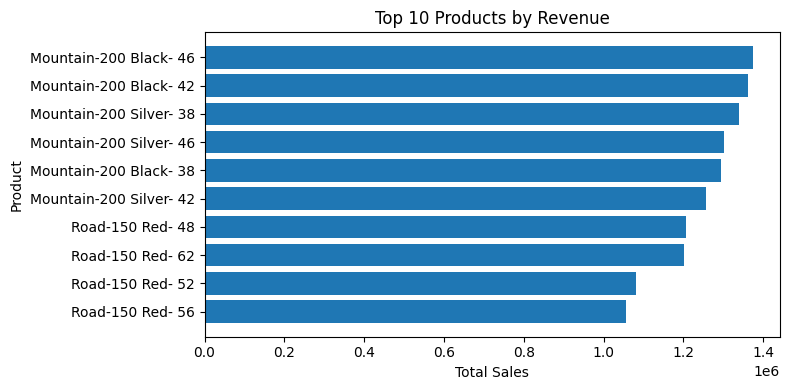

In [29]:
#Visualize top products
plt.figure(figsize=(8, 4))

plt.barh(
    top_products["product_name"],
    top_products["total_sales"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [25]:
#Top 10 customers by spending
#Business question: Who are our highest-value customers based on total spending?
query = """
SELECT
    c.customer_key,
    c.first_name,
    c.last_name,
    SUM(f.sales_amount) AS total_spending,
    COUNT(DISTINCT f.order_number) AS total_orders,
    SUM(f.quantity) AS total_quantity
FROM fact_sales f
LEFT JOIN dim_customers c
    ON f.customer_key = c.customer_key
GROUP BY
    c.customer_key,
    c.first_name,
    c.last_name
ORDER BY total_spending DESC
LIMIT 10
"""

top_customers = con.execute(query).df()
display(top_customers)

,customer_key,first_name,last_name,total_spending,total_orders,total_quantity
0,1133,Kaitlyn,Henderson,13294.0,5,14.0
1,1302,Nichole,Nara,13294.0,5,13.0
2,1309,Margaret,He,13268.0,5,14.0
3,1132,Randall,Dominguez,13265.0,5,11.0
4,1301,Adriana,Gonzalez,13242.0,5,10.0
5,1322,Rosa,Hu,13215.0,5,15.0
6,1125,Brandi,Gill,13195.0,5,12.0
7,1308,Brad,She,13172.0,5,11.0
8,1297,Francisco,Sara,13164.0,5,12.0
9,434,Maurice,Shan,12914.0,6,13.0


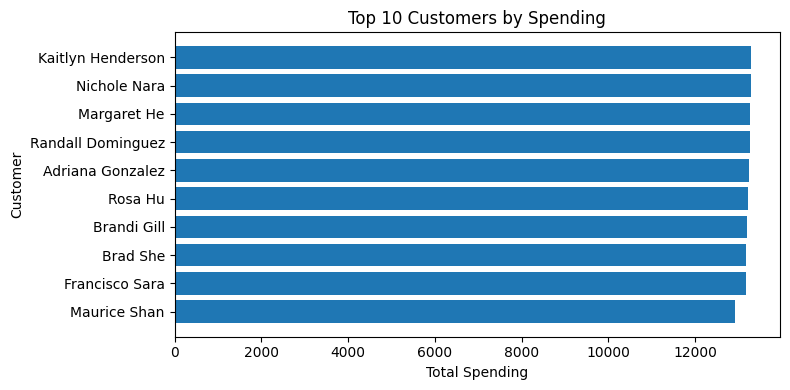

In [28]:
#Chart top customers
top_customers["customer_name"] = (
    top_customers["first_name"] + " " +
    top_customers["last_name"]
)

plt.figure(figsize=(8, 4))

plt.barh(
    top_customers["customer_name"],
    top_customers["total_spending"]
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#Interpretation: These customers contribute the most revenue. The business may prioritize customer retention, loyalty benefits, and personalized offers.

### **4. Customer Segmentation Analysis**

Here we divide customers into groups based on their total spending.
Segment customers

We will use three categories:

- VIP → customers spending above $5,000

- Regular → customers spending $1,000 - $5,000

- Low spender → customers spending below $1,000

In [30]:
query = """
WITH customer_spending AS (
    SELECT
        f.customer_key,
        c.first_name,
        c.last_name,
        SUM(f.sales_amount) AS total_spending
    FROM fact_sales f
    LEFT JOIN dim_customers c
        ON f.customer_key = c.customer_key
    GROUP BY
        f.customer_key,
        c.first_name,
        c.last_name
)

SELECT
    customer_key,
    first_name,
    last_name,
    total_spending,
    CASE
        WHEN total_spending > 5000 THEN 'VIP'
        WHEN total_spending >= 1000 THEN 'Regular'
        ELSE 'Low Spender'
    END AS customer_segment
FROM customer_spending
ORDER BY total_spending DESC
"""

customer_segments = con.execute(query).df()
display(customer_segments.head(20))

,customer_key,first_name,last_name,total_spending,customer_segment
0,1302,Nichole,Nara,13294.0,VIP
1,1133,Kaitlyn,Henderson,13294.0,VIP
2,1309,Margaret,He,13268.0,VIP
3,1132,Randall,Dominguez,13265.0,VIP
4,1301,Adriana,Gonzalez,13242.0,VIP
5,1322,Rosa,Hu,13215.0,VIP
6,1125,Brandi,Gill,13195.0,VIP
7,1308,Brad,She,13172.0,VIP
8,1297,Francisco,Sara,13164.0,VIP
9,434,Maurice,Shan,12914.0,VIP


In [31]:
# Customer segment distribution
segment_summary = (
    customer_segments
    .groupby("customer_segment")
    .agg(
        customer_count=("customer_key", "count"),
        total_spending=("total_spending", "sum")
    )
    .reset_index()
)

display(segment_summary)

,customer_segment,customer_count,total_spending
0,Low Spender,10788,1510725.0
1,Regular,5964,16592551.0
2,VIP,1732,11252974.0


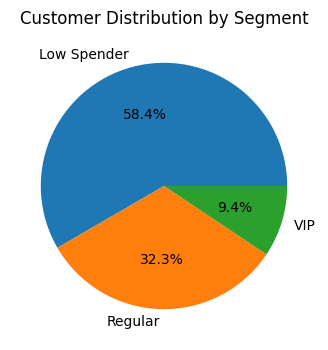

In [33]:
# Visualize customer segments
plt.figure(figsize=(4, 4))

plt.pie(
    segment_summary["customer_count"],
    labels=segment_summary["customer_segment"],
    autopct="%1.1f%%"
)

plt.title("Customer Distribution by Segment")
plt.show()

# Interpretation: Are most customers VIP, regular, or low-spending? Are there few high-value customers generating a large portion of the revenue?

### **5. Time-Series Analysis**

Time analysis helps us understand how business performance changes over time.

In [35]:
# Monthly revenue trend
query = """
SELECT
    DATE_TRUNC('month', CAST(order_date AS DATE)) AS sales_month,
    SUM(sales_amount) AS total_sales,
    SUM(quantity) AS total_quantity,
    COUNT(DISTINCT order_number) AS total_orders
FROM fact_sales
WHERE order_date IS NOT NULL
GROUP BY sales_month
ORDER BY sales_month
LIMIT 10
"""

monthly_sales = con.execute(query).df()
display(monthly_sales)

,sales_month,total_sales,total_quantity,total_orders
0,2010-12-01,43419.0,14.0,14
1,2011-01-01,469795.0,144.0,144
2,2011-02-01,466307.0,144.0,144
3,2011-03-01,485165.0,150.0,150
4,2011-04-01,502042.0,157.0,157
5,2011-05-01,561647.0,174.0,174
6,2011-06-01,737793.0,230.0,230
7,2011-07-01,596710.0,188.0,188
8,2011-08-01,614516.0,193.0,193
9,2011-09-01,603047.0,185.0,185


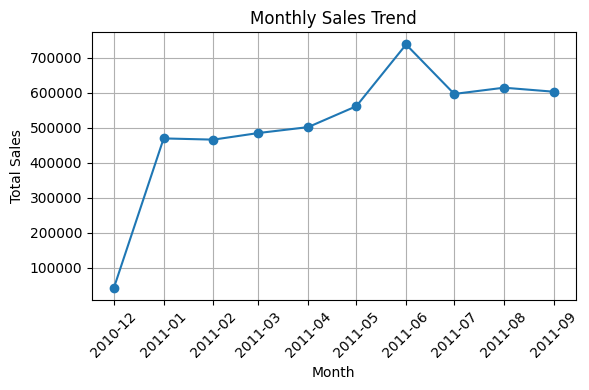

In [37]:
# Plot monthly revenue
plt.figure(figsize=(6, 4))

plt.plot(
    monthly_sales["sales_month"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

#Interpretation: Identify sales peaks, declines, growth periods, and seasonality

In [38]:
# Yearly revenue
query = """
SELECT
    EXTRACT(YEAR FROM CAST(order_date AS DATE)) AS sales_year,
    SUM(sales_amount) AS total_sales,
    SUM(quantity) AS total_quantity,
    COUNT(DISTINCT order_number) AS total_orders
FROM fact_sales
WHERE order_date IS NOT NULL
GROUP BY sales_year
ORDER BY sales_year
"""

yearly_sales = con.execute(query).df()
display(yearly_sales)

,sales_year,total_sales,total_quantity,total_orders
0,2010,43419.0,14.0,14
1,2011,7075088.0,2216.0,2216
2,2012,5842231.0,3397.0,3269
3,2013,16344878.0,52807.0,21287
4,2014,45642.0,1970.0,871


In [39]:
# Year-over-year growth
query = """
WITH yearly AS (
    SELECT
        EXTRACT(YEAR FROM CAST(order_date AS DATE)) AS sales_year,
        SUM(sales_amount) AS total_sales
    FROM fact_sales
    WHERE order_date IS NOT NULL
    GROUP BY sales_year
)

SELECT
    sales_year,
    total_sales,
    LAG(total_sales) OVER (
        ORDER BY sales_year
    ) AS previous_year_sales,

    ROUND(
        100.0 * (total_sales - LAG(total_sales) OVER (
            ORDER BY sales_year
        )) / NULLIF(
            LAG(total_sales) OVER (
                ORDER BY sales_year
            ), 0
        ),
        2
    ) AS yoy_growth_percentage

FROM yearly
ORDER BY sales_year
"""

yearly_growth = con.execute(query).df()
display(yearly_growth)

# Interpretation: We can measure whether sales are growing or declining compared with the previous year.

,sales_year,total_sales,previous_year_sales,yoy_growth_percentage
0,2010,43419.0,NaN,NaN
1,2011,7075088.0,43419.0,16194.91
2,2012,5842231.0,7075088.0,-17.43
3,2013,16344878.0,5842231.0,179.77
4,2014,45642.0,16344878.0,-99.72


### **6. Cumulative Analysis**

Cumulative analysis tells us how sales accumulate over time.

For example:

- January revenue = 100
- February revenue = 200
- March revenue = 300

Cumulative revenue becomes 100 → 300 → 600.

In [41]:
#Running total of sales
query = """
WITH monthly AS (
    SELECT
        DATE_TRUNC('month', CAST(order_date AS DATE)) AS sales_month,
        SUM(sales_amount) AS monthly_sales
    FROM fact_sales
    WHERE order_date IS NOT NULL
    GROUP BY sales_month
)

SELECT
    sales_month,
    monthly_sales,

    SUM(monthly_sales) OVER (
        ORDER BY sales_month
        ROWS BETWEEN UNBOUNDED PRECEDING
        AND CURRENT ROW
    ) AS cumulative_sales

FROM monthly
ORDER BY sales_month
LIMIT 10
"""

cumulative_sales = con.execute(query).df()
display(cumulative_sales)

,sales_month,monthly_sales,cumulative_sales
0,2010-12-01,43419.0,43419.0
1,2011-01-01,469795.0,513214.0
2,2011-02-01,466307.0,979521.0
3,2011-03-01,485165.0,1464686.0
4,2011-04-01,502042.0,1966728.0
5,2011-05-01,561647.0,2528375.0
6,2011-06-01,737793.0,3266168.0
7,2011-07-01,596710.0,3862878.0
8,2011-08-01,614516.0,4477394.0
9,2011-09-01,603047.0,5080441.0


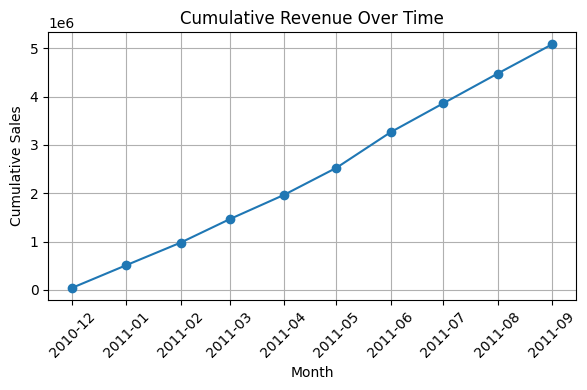

In [43]:
# Cumulative revenue chart
plt.figure(figsize=(6, 4))

plt.plot(
    cumulative_sales["sales_month"],
    cumulative_sales["cumulative_sales"],
    marker="o"
)

plt.title("Cumulative Revenue Over Time")
plt.xlabel("Month")
plt.ylabel("Cumulative Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

#Why is this useful?
#It helps management track the total revenue accumulated during the period and compare progress against business targets.

### **7. Performance Analysis**
Here we compare individual products with overall product performance.

In [44]:
# Products compared against average sales
# Business question: Which products sell above or below the average product revenue?

query = """
WITH product_sales AS (
    SELECT
        p.product_name,
        p.category,
        SUM(f.sales_amount) AS total_sales
    FROM fact_sales f
    LEFT JOIN dim_products p
        ON f.product_key = p.product_key
    GROUP BY
        p.product_name,
        p.category
)

SELECT
    product_name,
    category,
    total_sales,

    AVG(total_sales) OVER () AS average_product_sales,

    CASE
        WHEN total_sales > AVG(total_sales) OVER ()
            THEN 'Above Average'
        WHEN total_sales < AVG(total_sales) OVER ()
            THEN 'Below Average'
        ELSE 'Average'
    END AS performance

FROM product_sales
ORDER BY total_sales DESC
"""

product_performance = con.execute(query).df()
display(product_performance)

,product_name,category,total_sales,average_product_sales,performance
0,Mountain-200 Black- 46,Bikes,1373454.0,225817.307692,Above Average
1,Mountain-200 Black- 42,Bikes,1363128.0,225817.307692,Above Average
2,Mountain-200 Silver- 38,Bikes,1339394.0,225817.307692,Above Average
3,Mountain-200 Silver- 46,Bikes,1301029.0,225817.307692,Above Average
4,Mountain-200 Black- 38,Bikes,1294854.0,225817.307692,Above Average
...,...,...,...,...,...
125,Touring Tire Tube,Accessories,7440.0,225817.307692,Below Average
126,Bike Wash - Dissolver,Accessories,7272.0,225817.307692,Below Average
127,Patch Kit/8 Patches,Accessories,6382.0,225817.307692,Below Average
128,Racing Socks- M,Clothing,2682.0,225817.307692,Below Average


In [45]:
# Count products in each performance group
performance_summary = (
    product_performance
    .groupby("performance")
    .size()
    .reset_index(name="product_count")
)

display(performance_summary)

,performance,product_count
0,Above Average,36
1,Below Average,94


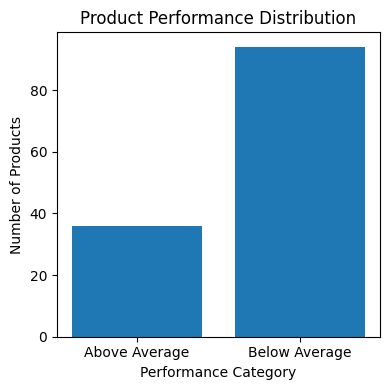

In [49]:
plt.figure(figsize=(4, 4))

plt.bar(
    performance_summary["performance"],
    performance_summary["product_count"]
)

plt.title("Product Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

# Interpretation: This helps identify how many products outperform the average and how many might need investigation.

### **8. Part-to-Whole Analysis**
Now we'll find how much each product category contributes to total revenue.

In [50]:
# Category contribution percentage

query = """
WITH category_sales AS (
    SELECT
        p.category,
        SUM(f.sales_amount) AS total_sales
    FROM fact_sales f
    LEFT JOIN dim_products p
        ON f.product_key = p.product_key
    GROUP BY p.category
)

SELECT
    category,
    total_sales,

    ROUND(
        100.0 * total_sales /
        NULLIF(SUM(total_sales) OVER (), 0),
        2
    ) AS sales_percentage

FROM category_sales
ORDER BY total_sales DESC
"""

category_contribution = con.execute(query).df()
display(category_contribution)

,category,total_sales,sales_percentage
0,Bikes,28316272.0,96.46
1,Accessories,700262.0,2.39
2,Clothing,339716.0,1.16


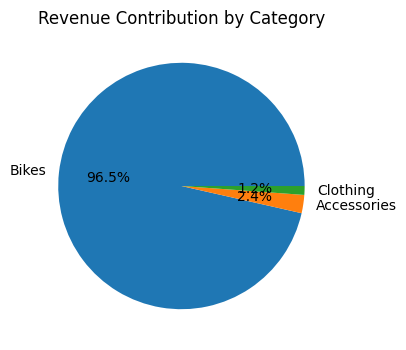

In [52]:
# Category contribution chart
plt.figure(figsize=(4, 4))

plt.pie(
    category_contribution["total_sales"],
    labels=category_contribution["category"],
    autopct="%1.1f%%"
)

plt.title("Revenue Contribution by Category")
plt.show()

#Interpretation: If a category contributes a large percentage of total revenue, the business may be highly dependent on it. That creates an opportunity to diversify or strengthen other categories.

### **9. Drill-down and Roll-up Analysis**
This is an important OLAP concept to know for interviews.

- Roll-up: Move from detailed data to summarized data.
- Drill-down: Move from summarized data to more detailed data.

For example:

Sales hierarchy

Yearly sales -> Quarterly sales -> Monthly sales -> Daily sales

In [54]:
#Roll-up: Yearly sales by category
query = """
SELECT
    EXTRACT(YEAR FROM CAST(f.order_date AS DATE)) AS sales_year,
    p.category,
    SUM(f.sales_amount) AS total_sales
FROM fact_sales f
LEFT JOIN dim_products p
    ON f.product_key = p.product_key
WHERE f.order_date IS NOT NULL
GROUP BY
    sales_year,
    p.category
ORDER BY
    sales_year,
    total_sales DESC
"""

year_category_sales = con.execute(query).df()
display(year_category_sales)

,sales_year,category,total_sales
0,2010,Bikes,43419.0
1,2011,Bikes,7075088.0
2,2012,Bikes,5839443.0
3,2012,Accessories,2146.0
4,2012,Clothing,642.0
5,2013,Bikes,15353707.0
6,2013,Accessories,667431.0
7,2013,Clothing,323740.0
8,2014,Accessories,30332.0
9,2014,Clothing,15310.0


In [55]:
# Drill-down: Monthly sales by category
query = """
SELECT
    DATE_TRUNC('month', CAST(f.order_date AS DATE)) AS sales_month,
    p.category,
    SUM(f.sales_amount) AS total_sales
FROM fact_sales f
LEFT JOIN dim_products p
    ON f.product_key = p.product_key
WHERE f.order_date IS NOT NULL
GROUP BY
    sales_month,
    p.category
ORDER BY
    sales_month,
    total_sales DESC
"""

monthly_category_sales = con.execute(query).df()
display(monthly_category_sales)

# Interpretation: We can view total category performance at yearly level and then drill into monthly details to understand exactly when performance changed.

,sales_month,category,total_sales
0,2010-12-01,Bikes,43419.0
1,2011-01-01,Bikes,469795.0
2,2011-02-01,Bikes,466307.0
3,2011-03-01,Bikes,485165.0
4,2011-04-01,Bikes,502042.0
...,...,...,...
60,2013-12-01,Bikes,1773645.0
61,2013-12-01,Accessories,65717.0
62,2013-12-01,Clothing,34766.0
63,2014-01-01,Accessories,30332.0


### **10. Advanced SQL — Customer ranking with window functions**
We have already used LAG() and cumulative SUM(). Let's use RANK() to rank customers based on spending.

In [56]:
# Rank customers
query = """
WITH customer_sales AS (
    SELECT
        c.customer_key,
        c.first_name,
        c.last_name,
        SUM(f.sales_amount) AS total_spending
    FROM fact_sales f
    LEFT JOIN dim_customers c
        ON f.customer_key = c.customer_key
    GROUP BY
        c.customer_key,
        c.first_name,
        c.last_name
)

SELECT
    customer_key,
    first_name,
    last_name,
    total_spending,

    RANK() OVER (
        ORDER BY total_spending DESC
    ) AS customer_rank

FROM customer_sales
ORDER BY customer_rank
"""

customer_ranking = con.execute(query).df()
display(customer_ranking.head(20))

,customer_key,first_name,last_name,total_spending,customer_rank
0,1302,Nichole,Nara,13294.0,1
1,1133,Kaitlyn,Henderson,13294.0,1
2,1309,Margaret,He,13268.0,3
3,1132,Randall,Dominguez,13265.0,4
4,1301,Adriana,Gonzalez,13242.0,5
5,1322,Rosa,Hu,13215.0,6
6,1125,Brandi,Gill,13195.0,7
7,1308,Brad,She,13172.0,8
8,1297,Francisco,Sara,13164.0,9
9,434,Maurice,Shan,12914.0,10


### SQL function	Purpose

RANK() ->	Assigns ranking

SUM() -> Calculates spending

GROUP BY ->	Aggregates sales per customer

ORDER BY ->	Sorts highest spending first


### **Business Insights Report**
Now we need to convert our analysis into something a business person can understand.

In [57]:
#Generate an automatic summary
total_revenue = kpi.loc[0, "total_revenue"]
total_orders = kpi.loc[0, "total_orders"]
total_customers = kpi.loc[0, "total_customers"]

best_category = category_sales.iloc[0]["category"]
best_category_revenue = category_sales.iloc[0]["total_sales"]

best_country = country_sales.iloc[0]["country"]
best_country_revenue = country_sales.iloc[0]["total_sales"]

best_product = top_products.iloc[0]["product_name"]
best_product_revenue = top_products.iloc[0]["total_sales"]

best_customer = (
    top_customers.iloc[0]["first_name"] + " " +
    top_customers.iloc[0]["last_name"]
)

best_customer_spending = top_customers.iloc[0]["total_spending"]

print("========== BUSINESS INSIGHTS ==========")

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")

print(
    f"\nHighest Revenue Category: {best_category} "
    f"({best_category_revenue:,.2f})"
)

print(
    f"Top Country: {best_country} "
    f"({best_country_revenue:,.2f})"
)

print(
    f"Best Selling Product by Revenue: {best_product} "
    f"({best_product_revenue:,.2f})"
)

print(
    f"Highest Spending Customer: {best_customer} "
    f"({best_customer_spending:,.2f})"
)

print("====================================")

========== BUSINESS INSIGHTS ==========
Total Revenue: 29,356,250.00
Total Orders: 27,659
Total Customers: 18,484

Highest Revenue Category: Bikes (28,316,272.00)
Top Country: Australia  (9,060,172.00)
Best Selling Product by Revenue: Mountain-200 Black- 46 (1,373,454.00)
Highest Spending Customer: Kaitlyn Henderson (13,294.00)


In [58]:
#Export analysis results
# This allows you to save your analysis tables as CSV files.
category_sales.to_csv("category_sales_analysis.csv", index=False)
country_sales.to_csv("country_sales_analysis.csv", index=False)
top_products.to_csv("top_products_analysis.csv", index=False)
top_customers.to_csv("top_customers_analysis.csv", index=False)
customer_segments.to_csv("customer_segments_analysis.csv", index=False)
monthly_sales.to_csv("monthly_sales_analysis.csv", index=False)
yearly_growth.to_csv("yearly_sales_growth.csv", index=False)
cumulative_sales.to_csv("cumulative_sales_analysis.csv", index=False)
product_performance.to_csv("product_performance_analysis.csv", index=False)
category_contribution.to_csv("category_contribution_analysis.csv", index=False)
customer_ranking.to_csv("customer_ranking_analysis.csv", index=False)

print("All analysis results exported successfully!")

All analysis results exported successfully!


In [59]:
# DOWNLOAD Results
files.download("category_sales_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Business Insights & Recommendations**

1\. **Overall Business Performance:** Generated total revenue of 29.36 million through 27,659 orders from 18,484 unique customers, indicating significant sales activity.

2\. **Product Category Performance:** Bikes contributed approximately 96.46% of total revenue, highlighting heavy dependence on the Bikes category. The business should explore opportunities to increase sales of accessories and other categories.

3\. **Geographical Performance:** Australia emerged as the highest-revenue-generating market, contributing approximately 30.85% of total revenue. The company should focus on maintaining its market presence and exploring further growth opportunities.

4\. **Top Product Performance:** Mountain-200 Black-46 generated the highest product revenue of 1,373,454. Maintaining inventory availability and monitoring its sales performance could help sustain revenue.

5\. **Customer Analysis:** Kaitlyn Henderson was the highest-spending customer, contributing 13,294 in purchases. Identifying similar high-value customers and introducing targeted loyalty initiatives could improve customer retention.

6\. **Revenue Diversification:** Since the Bikes category accounts for most revenue, expanding sales across other product categories could reduce business dependence on a single category.

7\. **Business Monitoring:** Regularly tracking revenue, order volume, customer activity, product performance, and geographical sales can help management identify growth opportunities and make data-driven decisions.